# 02 — Expected-consumption models (baselines → Ridge → LightGBM)

**Goal:** for every hour and every circuit, predict how much electricity the circuit *should* use. In notebook 03 we compare
this "expected" value with the real use: a large positive gap = possible waste.

**What we take from notebook 01 (EDA):**
* target = energy per hour (Wh = mean W) per circuit; NW Plugs & Sockets first (45 % of all use)
* drivers: hour of day × working day, holidays / breaks, outdoor temperature (heaters, non-linear), slow growth over years
* strong memory at 24 h and 1 week → lags help, but must be ≥ 24 h old
* validation must respect time (no random split); lockdown removed

**Model ladder** (lecture: *start with the simplest useful model, then earn complexity*):

| Model | Idea | Why it is in the ladder |
|---|---|---|
| B1 last week | same hour, 7 days earlier | the naive yardstick |
| B2 4-week median | median of the same hour in the last 4 weeks | robust naive yardstick |
| B3 profile | median per (working day?, hour) from training | "typical day", no memory, no weather |
| Ridge | linear regression + L2, hand-made interactions | simple, explainable; tells us if a linear model is enough |
| LightGBM | gradient-boosted trees, L1 loss | strong for tabular data, learns interactions & non-linear temperature effect itself |

Each of Ridge and LightGBM is trained with two feature sets (see `src/features.py`):
* **forecast** = calendar + weather + lags (24 h, 48 h, 1 w, 2 w, mean of last 7 days at that hour)
* **normal** = calendar + weather + a slow *level* (median working-hour use of the last 28 days) — no recent lags, so long-lasting waste is not learned as normal

**Metrics** (all in kWh per hour): **MAE** = main metric (average miss, easy to explain to the client), RMSE (punishes big misses),
CV(RMSE) = RMSE / mean (ASHRAE Guideline 14 uses < 30 % for hourly models), NMBE = bias (does the model systematically over/under-predict?).

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load, short, FOCUS, FIG, ROOT
from src.features import make_features, split_of, SPLITS, feature_lags
from src.models import evaluate_circuit, LGB_GRID

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
REP = ROOT / "reports"
def save(fig, name): fig.savefig(FIG / f"model_{name}.png", bbox_inches="tight")

df = load()                       # lockdown removed
df["split"] = split_of(df["timestamp_local"])
df.groupby("split")["timestamp_local"].agg(["min", "max", "size"]).loc[["train", "val", "test", "regime_b"]]

,min,max,size
split,,,
train,2020-06-22 00:00:00,2022-08-31 23:00:00,19224
val,2022-09-01 00:00:00,2022-12-31 23:00:00,2929
test,2023-01-01 00:00:00,2023-02-28 23:00:00,1416
regime_b,2025-08-18 20:00:00,2025-10-13 16:00:00,1341


## 1. Time split — train → validate → test (and an out-of-time check)

* **train** Jun 2020 – Aug 2022: fit the models (two full winters)
* **validation** Sep – Dec 2022: choose settings (hyper-parameters, Ridge α) and compare models
* **test** Jan – Feb 2023: touched **once**, after everything is fixed, with models refitted on train + validation
* **Regime B** Aug – Oct 2025: models refitted on all 2020-23 data; does the building still behave the same 2.5 years later?

Random cross-validation is not used: it would mix future and past hours and give too optimistic scores (lecture slide 41).

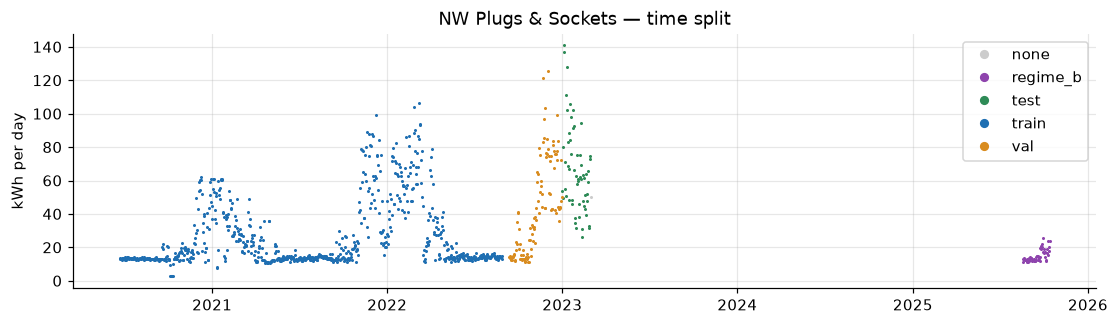

In [2]:
T = "NW|Plugs & Sockets W"
colors = {"train": "#1f6fb2", "val": "#d98c1f", "test": "#2e8b57", "regime_b": "#8e44ad", "none": "#cccccc"}
fig, ax = plt.subplots(figsize=(12, 3))
for sp, g in df.groupby("split"):
    d = g.set_index("timestamp_local")[T].resample("D").mean() * 24 / 1000
    ax.plot(d.index, d.values, ".", ms=2, color=colors[sp], label=sp)
ax.set_ylabel("kWh per day"); ax.set_title(f"{short(T)} — time split"); ax.legend(markerscale=5)
save(fig, "01_split"); plt.show()

## 2. Features — and how we prevent leakage

In [3]:
Xf = make_features(df, T, "forecast")
Xn = make_features(df, T, "normal")
desc = {
 "hour, weekday": "local hour 0-23, day of week", "is_working_day / is_holiday / is_break / is_august_closure": "calendar (UPM + Madrid)",
 "doy_sin, doy_cos": "position in the year (season), as a circle so Dec 31 is next to Jan 1",
 "wx_temp_c, heating_deg, cooling_deg": "outdoor temperature, max(0, 15-T), max(0, T-24)", "wx_solar_wm2, wx_humidity_pct": "outdoor sun and humidity",
 "lag_24, lag_48, lag_168, lag_336, same_hour_mean_7d": "forecast set only: target 1 d, 2 d, 1 w, 2 w ago; mean of last 7 days at this hour",
 "level_work_28d": "normal set only: median use during working hours (9-17h) of working days in the last 28 days, >= 24 h old",
}
pd.Series(desc, name="meaning").to_frame()

,meaning
"hour, weekday","local hour 0-23, day of week"
is_working_day / is_holiday / is_break / is_august_closure,calendar (UPM + Madrid)
"doy_sin, doy_cos","position in the year (season), as a circle so ..."
"wx_temp_c, heating_deg, cooling_deg","outdoor temperature, max(0, 15-T), max(0, T-24)"
"wx_solar_wm2, wx_humidity_pct",outdoor sun and humidity
"lag_24, lag_48, lag_168, lag_336, same_hour_mean_7d","forecast set only: target 1 d, 2 d, 1 w, 2 w a..."
level_work_28d,normal set only: median use during working hou...


In [4]:
# Leakage check (same idea as tests/test_features.py): change the future, the past features must not change.
k = 15_000
df2 = df.copy(); df2.loc[k:, T] = 1e6
for kind in ["forecast", "normal"]:
    a, b = make_features(df, T, kind), make_features(df2, T, kind)
    cols = feature_lags(a)
    same = a.loc[:k + 23, cols].equals(b.loc[:k + 23, cols])
    print(f"{kind:8s}: features up to 24 h after the change are identical -> {same}")
print("No same-hour measurements (W, I, Pa, Ea, indoor sensors) in the features:",
      not any(c.endswith(' W') or '|ENV' in c for c in Xf.columns.union(Xn.columns)))

forecast: features up to 24 h after the change are identical -> True
normal  : features up to 24 h after the change are identical -> True
No same-hour measurements (W, I, Pa, Ea, indoor sensors) in the features: True


**How leakage is prevented (defend point B):**
1. every value derived from the target is at least **24 h old** (we predict a whole day ahead);
2. lags are computed **inside each regime**: the 2.5-year gap is never bridged;
3. no measurement of the **same hour** is used (`W`, `I`, `Pa`, `Ea`, indoor lux / temperature are effects of the target);
4. the scaler and one-hot encoder of Ridge live inside a scikit-learn `Pipeline`, so they are **fitted on training rows only**;
5. settings are chosen on validation, the test period is used **once**;
6. `pytest` runs these checks automatically (`tests/test_features.py`).

## 3. Walk-through on NW Plugs & Sockets
`evaluate_circuit` does the three steps of section 1 for every model. All models are scored on exactly the same hours.

In [5]:
res = evaluate_circuit(df, T)
r = res["results"]
tab = r.pivot_table(index="model", columns="period", values="MAE_kWh")[["val", "test", "regime_b"]]
tab["CV(RMSE) % test"] = r[r.period == "test"].set_index("model")["CV_RMSE_%"]
tab["NMBE % test"] = r[r.period == "test"].set_index("model")["NMBE_%"]
print("MAE in kWh per hour (lower is better)")
tab.sort_values("val").round(3)

MAE in kWh per hour (lower is better)


period,val,test,regime_b,CV(RMSE) % test,NMBE % test
model,,,,,
LightGBM_forecast,0.694,0.974,0.177,52.521,6.217
Ridge_forecast,0.726,1.046,0.238,53.801,-1.085
B2_median_4w,0.847,1.051,0.197,55.974,-7.898
LightGBM_normal,0.849,1.170,0.198,57.927,-8.586
B1_last_week,0.878,1.224,0.245,65.410,-5.628
Ridge_normal,0.906,1.250,0.360,59.946,-8.202
B3_profile,1.361,2.004,0.227,102.679,76.202


In [6]:
print("Chosen LightGBM settings (forecast):", res["lgb_params_forecast"], " Ridge alpha:", res["ridge_alpha_forecast"])
print("Top 5 of the validation search (forecast set):")
res["lgb_log_forecast"].head(5)[list(LGB_GRID) + ["MAE_kWh", "CV_RMSE_%"]].round(3)

Chosen LightGBM settings (forecast): {'num_leaves': 15, 'learning_rate': 0.03, 'n_estimators': 600, 'min_child_samples': 20}  Ridge alpha: 0.1
Top 5 of the validation search (forecast set):


,num_leaves,learning_rate,n_estimators,min_child_samples,MAE_kWh,CV_RMSE_%
0,15,0.03,600,20,0.694,57.471
1,15,0.03,600,80,0.700,57.817
2,15,0.10,600,20,0.705,58.520
5,63,0.03,600,80,0.709,58.721
3,15,0.10,600,80,0.714,58.794


**→ Finding:** For NW Plugs, **LightGBM_forecast is the best model on validation (MAE 0.69 kWh/h) and on test (0.97)**, about 18 % better than the best naive baseline on validation and 7 % on test. Ridge_forecast is close behind (0.73 / 1.05): most of the signal is already captured by a linear model on the right features. The *normal* models (no recent lags) are only about as good as the 4-week median. B3 (fixed profile without weather) is clearly the worst: it misses the heating season. The test errors are higher than validation because January–February is the coldest and most variable period (the CV(RMSE) of ≈ 53 % is above the ASHRAE 30 % target: individual heaters switched on by people are hard to predict hour by hour). In 2025 (summer, no heating) the error is much smaller. The validation search shows that small trees (15 leaves) with a slow learning rate work best: the differences between settings are small (0.694 – 0.714), so the result is not sensitive to tuning.

### What do the predictions look like?
A normal winter week and the first week of January (Christmas break, building closed until 6 Jan).

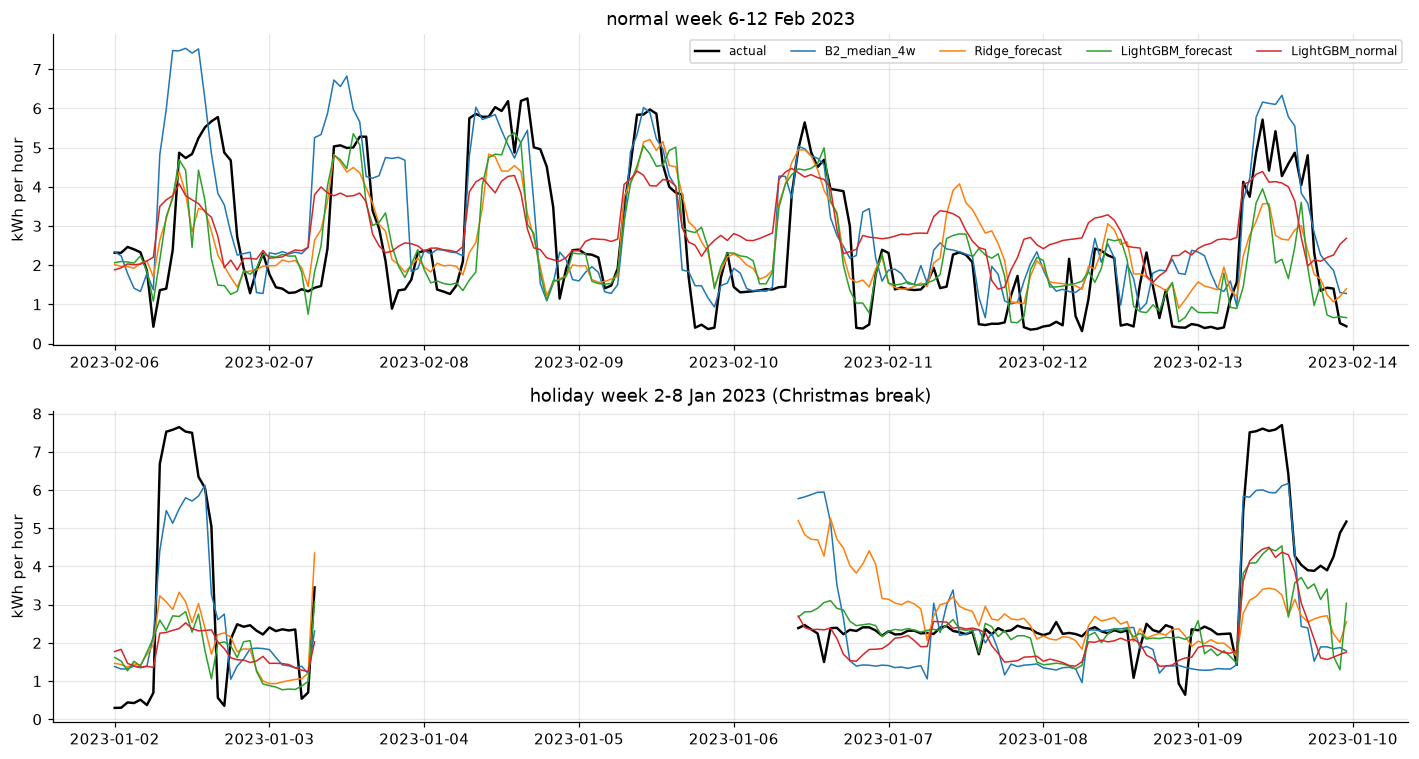

In [7]:
P = res["predictions"]["test"].set_index("timestamp_local")
show = ["B2_median_4w", "Ridge_forecast", "LightGBM_forecast", "LightGBM_normal"]
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, (a, b, title) in zip(axes, [("2023-02-06", "2023-02-13", "normal week 6-12 Feb 2023"),
                                     ("2023-01-02", "2023-01-09", "holiday week 2-8 Jan 2023 (Christmas break)")]):
    w = P.loc[a:b].asfreq("h")
    ax.plot(w.index, w["actual"] / 1000, color="black", lw=1.6, label="actual")
    for c in show:
        ax.plot(w.index, w[c] / 1000, lw=1, label=c)
    ax.set_title(title); ax.set_ylabel("kWh per hour")
axes[0].legend(ncol=5, fontsize=8, loc="upper right")
fig.tight_layout(); save(fig, "02_weeks_NW_plugs"); plt.show()

**→ Finding:** On working days all models follow the shape (on at 7:00, off in the evening). The models under-predict the highest peaks and **over-predict weekend nights** (actual ≈ 0.4–0.5 kWh/h, expected ≈ 1.5–2.5): on some weekends the heaters *are* switched off, which shows that the high level on other weekends is avoidable. The holiday week reveals a **calendar problem**: on Monday 2 January 2023 the building was used like a normal working day (7.5 kWh/h), but `build_calendar.py` assumes the Christmas break lasts until 6 January. The models believe it is a closed day and under-predict strongly. **Action for the group:** check the real UPM closure dates; until then, anomaly flags on break days must be read with care. (3–6 January are missing in the data.)

### What did the models learn?
Feature importance of LightGBM = how much each feature reduced the error ("gain"), from the models used on the test period.

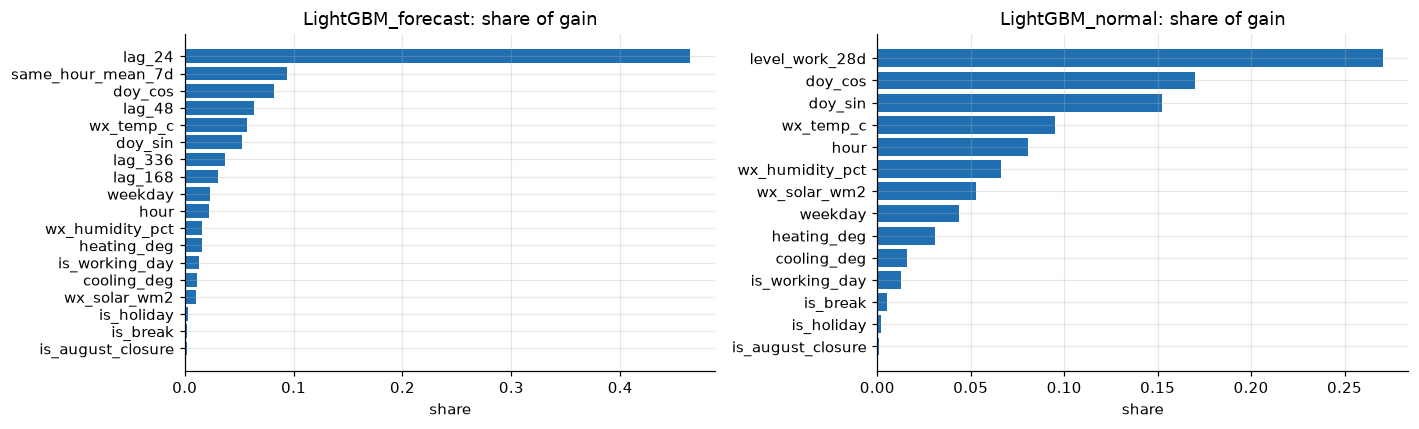

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, k in zip(axes, ["forecast", "normal"]):
    imp = res[f"importance_{k}"]; imp = (imp / imp.sum()).sort_values()
    ax.barh(imp.index, imp.values, color="#1f6fb2"); ax.set_title(f"LightGBM_{k}: share of gain"); ax.set_xlabel("share")
fig.tight_layout(); save(fig, "03_importance_NW_plugs"); plt.show()

**→ Finding:** The forecast model relies mostly on **yesterday's value at the same hour** (`lag_24`, ≈ 45 % of the gain), then the 7-day mean and the season. The normal model, which may not look at the recent past, uses the **28-day working level, the season and outdoor temperature** instead. This matches the EDA: memory + season + temperature. The calendar flags matter less than expected because `lag_24` and `weekday` already carry most of that information.

## 4. All focus circuits
Same procedure for the 9 focus circuits (≈ 5 minutes). Results are saved to `reports/model_comparison.csv`.

In [9]:
results, params, test_preds = [res["results"]], {T: {k: res[f"lgb_params_{k}"] for k in ["forecast", "normal"]}}, {T: res["predictions"]}
for c in FOCUS:
    if c == T:
        continue
    rc = evaluate_circuit(df, c)
    results.append(rc["results"]); params[c] = {k: rc[f"lgb_params_{k}"] for k in ["forecast", "normal"]}
    test_preds[c] = rc["predictions"]
    print("done", short(c))
allres = pd.concat(results, ignore_index=True)
allres.to_csv(REP / "model_comparison.csv", index=False)
json.dump({short(k): v for k, v in params.items()}, open(REP / "model_params.json", "w"), indent=2)
pd.concat({short(c): p["test"] for c, p in test_preds.items()}, names=["circuit"]).to_parquet(REP / "test_predictions.parquet")

done SW Plugs & Sockets


done SE Plugs & Sockets


done NE Plugs & Sockets


done NW Lighting


done SW Lighting


done SE Lighting


done NW HVAC


done SE HVAC


In [10]:
def table(period, value="MAE_kWh"):
    t = allres[allres.period == period].pivot_table(index="circuit", columns="model", values=value)
    t.index = [short(i) for i in t.index]
    return t

val = table("val")
best = val.idxmin(axis=1).rename("best on validation")
skill = (1 - val.div(val[["B1_last_week", "B2_median_4w"]].min(axis=1), axis=0)) * 100
print("Validation MAE (kWh/h); last column = model with the lowest MAE")
pd.concat([val.round(3), best], axis=1)

Validation MAE (kWh/h); last column = model with the lowest MAE


,B1_last_week,B2_median_4w,B3_profile,LightGBM_forecast,LightGBM_normal,Ridge_forecast,Ridge_normal,best on validation
NE Plugs & Sockets,0.052,0.069,0.072,0.028,0.071,0.032,0.070,LightGBM_forecast
NW HVAC,0.004,0.002,0.020,0.004,0.021,0.013,0.038,B2_median_4w
NW Lighting,0.121,0.107,0.094,0.065,0.129,0.102,0.178,LightGBM_forecast
NW Plugs & Sockets,0.878,0.847,1.361,0.694,0.849,0.726,0.906,LightGBM_forecast
SE HVAC,0.016,0.014,0.015,0.013,0.016,0.014,0.015,LightGBM_forecast
SE Lighting,0.144,0.121,0.108,0.106,0.108,0.127,0.118,LightGBM_forecast
SE Plugs & Sockets,0.076,0.054,0.282,0.078,0.129,0.071,0.102,B2_median_4w
SW Lighting,0.243,0.210,0.206,0.172,0.170,0.203,0.215,LightGBM_normal
SW Plugs & Sockets,0.074,0.078,0.086,0.058,0.082,0.057,0.085,Ridge_forecast


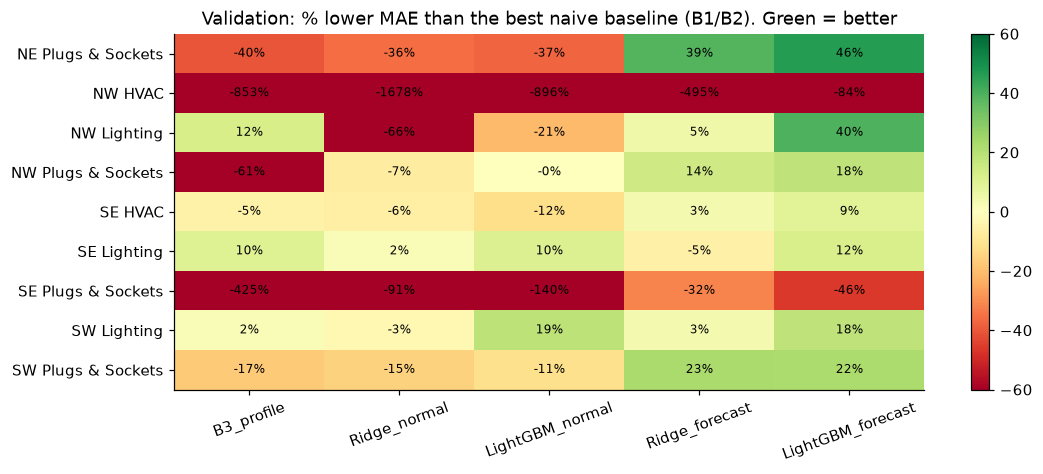

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.2))
cols = ["B3_profile", "Ridge_normal", "LightGBM_normal", "Ridge_forecast", "LightGBM_forecast"]
im = ax.imshow(skill[cols].clip(-60, 60), cmap="RdYlGn", vmin=-60, vmax=60, aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=20); ax.set_yticks(range(len(skill)), skill.index); ax.grid(False)
for i in range(len(skill)):
    for j, c in enumerate(cols):
        ax.text(j, i, f"{skill.iloc[i][c]:.0f}%", ha="center", va="center", fontsize=8)
ax.set_title("Validation: % lower MAE than the best naive baseline (B1/B2). Green = better")
fig.colorbar(im, ax=ax); save(fig, "04_skill_heatmap"); plt.show()

**→ Finding:** **LightGBM_forecast is the best or near-best model for 7 of the 9 circuits** (best on 5, within 0.002 kWh of the best on SW Lighting and SW Plugs), with 18–46 % lower error than the naive baselines on the plug circuits and NW Lighting. Ridge_forecast is a close second, and wins on SW Plugs. Two exceptions: **NW HVAC** and **SE Plugs**, where the 4-week median is best (very regular or very spiky circuits where 'same as the last weeks' is hard to beat). The *normal* feature set is clearly weaker almost everywhere (red/yellow cells), except for SW Lighting, which is driven purely by the calendar.

### Test period (used once) and the 2025 out-of-time check

In [12]:
test, rb = table("test"), table("regime_b")
cv = table("test", "CV_RMSE_%")
summary = pd.DataFrame({
    "MAE test B2": test["B2_median_4w"], "MAE test Ridge_f": test["Ridge_forecast"], "MAE test LGB_f": test["LightGBM_forecast"],
    "CV(RMSE)% test LGB_f": cv["LightGBM_forecast"],
    "MAE 2025 B2": rb["B2_median_4w"], "MAE 2025 LGB_f": rb["LightGBM_forecast"], "MAE 2025 LGB_n": rb["LightGBM_normal"],
})
summary.round(3)

,MAE test B2,MAE test Ridge_f,MAE test LGB_f,CV(RMSE)% test LGB_f,MAE 2025 B2,MAE 2025 LGB_f,MAE 2025 LGB_n
NE Plugs & Sockets,0.076,0.019,0.037,46.184,0.006,0.005,0.044
NW HVAC,0.113,0.064,0.060,60.660,0.072,0.055,0.061
NW Lighting,0.092,0.094,0.080,98.892,0.039,0.041,0.108
NW Plugs & Sockets,1.051,1.046,0.974,52.521,0.197,0.177,0.198
SE HVAC,0.035,0.035,0.036,52.434,0.008,0.018,0.023
SE Lighting,0.084,0.102,0.092,220.611,0.111,0.053,0.046
SE Plugs & Sockets,0.059,0.081,0.062,154.876,0.056,0.050,0.058
SW Lighting,0.206,0.242,0.209,96.590,0.025,0.016,0.039
SW Plugs & Sockets,0.160,0.103,0.088,46.820,0.034,0.039,0.098


**→ Finding:** On the test period, LightGBM_forecast stays best or tied for most circuits. Ridge wins on NE Plugs (close to linear), and the 4-week median wins on SE Lighting and ties on SE Plugs and SW Lighting. Circuits that are almost always 0 (SE Lighting) or very spiky (SE Plugs) have a CV(RMSE) far above 30 %. A percentage error on a value close to 0 is not meaningful, which is why MAE in kWh is our main metric. In the **2025 out-of-time check** the forecast model beats the 4-week median on 6 of 9 circuits and ties on a 7th, so a model trained on 2020-23 still works on the building 2.5 years later. Its lags adapt to the new level. The normal model is worse in 2025 for most circuits: without recent memory it does not adapt to changes in the building.

## 5. Residuals — the input for anomaly detection
Residual = actual − expected (LightGBM_forecast, test period). For anomaly detection we need to know how big a *normal* miss is,
and whether it depends on the time of day.

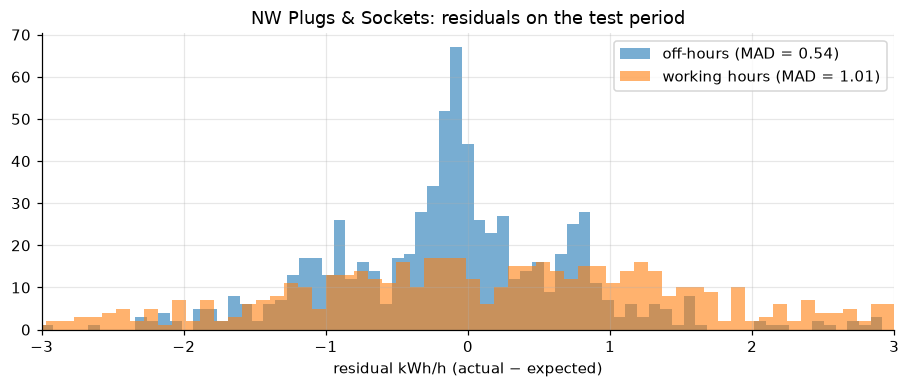

In [13]:
P = res["predictions"]["test"].copy()
P["resid_kWh"] = (P["actual"] - P["LightGBM_forecast"]) / 1000
meta = df.loc[P.index, ["is_off_hours"]]
P["hours"] = np.where(meta["is_off_hours"], "off-hours", "working hours")
fig, ax = plt.subplots(figsize=(10, 3.5))
for h, g in P.groupby("hours"):
    ax.hist(g["resid_kWh"], bins=100, alpha=0.6, label=f"{h} (MAD = {(g.resid_kWh - g.resid_kWh.median()).abs().median():.2f})")
ax.set_xlabel("residual kWh/h (actual − expected)"); ax.set_title(f"{short(T)}: residuals on the test period"); ax.legend()
ax.set_xlim(-3, 3); save(fig, "05_residuals"); plt.show()

**→ Finding:** Residuals are centred on 0 (no strong bias). Normal misses are **about twice as large during working hours (MAD ≈ 1.0 kWh/h) as off-hours (≈ 0.5)**. A single threshold for all hours would therefore either miss night waste or flood the client with daytime alarms. In notebook 03 the threshold is set **per circuit and per hour type** (working hours / off-hours) from these residuals.

## 6. Conclusions — defending the model (lecture: *final challenge*)

| Question | Our answer |
|---|---|
| **A. What exactly is the target?** | Energy used in each hour (Wh = mean W of that hour) per circuit, predicted one day ahead. Main circuit: NW Plugs & Sockets (45 % of Storey 1 use). |
| **B. How was leakage prevented?** | Only information ≥ 24 h old from the target, lags never cross the 2.5-year gap, no same-hour W/I/Pa/Ea or indoor sensors, scaler/encoder inside a Pipeline fitted on train only, time-ordered split with a test set used once, automatic checks in `tests/test_features.py`. |
| **C. Which metric matches the decision?** | MAE in kWh: the client thinks in kWh and €, and MAE is the average miss in those units. RMSE as secondary (large misses matter for false alarms), CV(RMSE) to compare with ASHRAE 14. Accuracy-style percentage metrics are unstable for circuits near 0. |
| **D. Why is this complexity justified?** | LightGBM beats every naive baseline on validation and test for the main circuits (≈ 7–46 % lower MAE), and Ridge shows that a linear model gets most of the way. The tuning search shows the result is not fragile. Deep learning is **not** used: tabular data, ~20k hours per circuit, and boosted trees already beat the baselines (lecture: tabular data favours tree ensembles). |

**Decision for notebook 03:**
1. *Expected* consumption = **LightGBM_forecast** (most accurate; the Ridge / B2 results are kept as a sanity check).
2. Because a lag model slowly learns long-lasting waste as normal, notebook 03 adds a second, transparent signal: **off-hours use above the standby level**.
3. Anomaly thresholds per circuit **and** per hour type (residual spread differs by a factor of ≈ 2).

**Limitations:** hourly CV(RMSE) is above the ASHRAE 30 % target for most circuits (occupant behaviour, no occupancy data), only 2 months of test data, the Christmas-break dates are an assumption that looks wrong for early January, and there is no ground truth for waste (validated with synthetic anomalies in notebook 03).